In [1]:
from setup_ipynb_paths import setup_project_root
PROJECT_ROOT = setup_project_root()
data_path = PROJECT_ROOT / "data"

import scripts.evaluation_utils as eval_utils
import scripts.desom as desom
import scripts.som as som
import scripts.ae_and_som as ae_som

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [5]:
def show_examples(X, y, n=10, per_label=False, labels=None, n_per_label=1, save_path=None):
    if labels is None:
        labels = list(range(10)) if per_label else None

    if labels is not None:
        total = len(labels) * n_per_label
        cols = len(labels)
        rows = n_per_label
        plt.figure(figsize=(1.6 * cols, 1.6 * rows))

        for label_idx, label in enumerate(labels):
            idxs = np.where(y == label)[0]
            for j in range(min(n_per_label, len(idxs))):
                i = idxs[j]
                ax = plt.subplot(rows, cols, j * cols + label_idx + 1)
                ax.imshow(X[i].reshape(28, 28), cmap="gray")
                ax.set_title(str(label))
                ax.axis("off")
    else:
        plt.figure(figsize=(12, 2))
        for i in range(n):
            plt.subplot(1, n, i + 1)
            plt.imshow(X[i].reshape(28, 28), cmap="gray")
            plt.title(str(y[i]))
            plt.axis("off")

    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", dpi=150)

    plt.show()

## **Chargement d'une partie de MNIST**

In [3]:
X_train, y_train, X_test, y_test = eval_utils.load_dataset(name="MNIST", root=data_path, n_train=10000, n_test=2000)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(10000, 784)
(10000,)
(2000, 784)
(2000,)


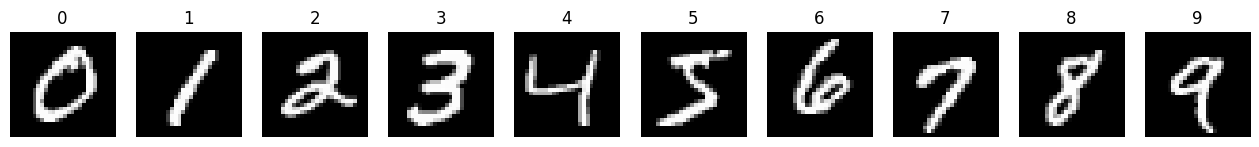

In [6]:
save_path = PROJECT_ROOT / "rapport/images"
show_examples(
    X_train,
    y_train,
    per_label=True,
    labels=list(range(10)),
    n_per_label=1,
    save_path=save_path / "mnist_examples_by_label.png",
)

In [ ]:
grid_size = (8, 8)

## **Pour Batch SOM**

In [6]:
batch_som = som.batchSOM(rayon_init=8.0, grid_size=grid_size, n_steps=250, dis_choice="euclidean", calculate_qe=True)
weights_som, history_som = batch_som.train(X_train)

results_som = eval_utils.evaluate_som_model(
    model_name="SOM",
    data=X_test,
    weights=weights_som,
    y_true=y_test,
    grid_size=grid_size,
    training_time=None
)
results_som

{'Modèle': 'SOM',
 'QE': np.float64(5.416463455385765),
 'TE': 0.4175,
 'Pureté': np.float64(0.7825),
 'NMI': 0.5429679861237993,
 'Grille': '8x8'}

## **Pour AE + Batch SOM**

In [7]:
ae_som_model = ae_som.AESOM(
    input_dim=784,
    latent_dim=10,
    rayon_init=8.0,
    grid_size=grid_size,
    n_steps_som=250,
    calculate_qe=True, 
    weight_init="random",
    dis_choice="euclidean",
    topology="rectangular"
)

ae_losses, weights_ae_som_r = ae_som_model.train_ae_n_som(X_train)

Z_test = ae_som_model.encode_latent(X_test)

weights_ae_som, history_ae_som = weights_ae_som_r

results_ae_som = eval_utils.evaluate_som_model(
    model_name="AE+SOM",
    data=Z_test,
    weights=weights_ae_som,
    y_true=y_test,
    grid_size=grid_size,
    training_time=None
)
results_ae_som
    

{'Modèle': 'AE+SOM',
 'QE': np.float64(1.2055992209549855),
 'TE': 0.466,
 'Pureté': np.float64(0.811),
 'NMI': 0.5639396391892287,
 'Grille': '8x8'}

## **Pour DESOM**

In [8]:
Desom_model = desom.DESOM(
    grid_size=grid_size,
    input_dim=784,
    latent_dim=10,
    n_epochs=100,
    batch_size=32,
    sigma_init=8.0,
    gamma=1e-3
)

desom_losses = Desom_model.embedded_train(X_train)

Z_test_desom = Desom_model.encode(X_test).detach().cpu().numpy()

weights_desom = Desom_model.som.weights.detach().cpu().numpy()

results_desom = eval_utils.evaluate_som_model(
    model_name="DESOM",
    data=Z_test_desom,
    weights=weights_desom,
    y_true=y_test,
    grid_size=grid_size,
    training_time=None
)
results_desom

{'Modèle': 'DESOM',
 'QE': np.float64(0.24654732309090135),
 'TE': 0.555,
 'Pureté': np.float64(0.825),
 'NMI': 0.5646330893392533,
 'Grille': '8x8'}

## **Creation de tableau**

In [9]:

list_results = [results_som, results_ae_som, results_desom]
df_results = eval_utils.create_results_dataframe_to_latex("resultats_des_metriques_mnist",list_results)

## **PROTOTYPE GRID**


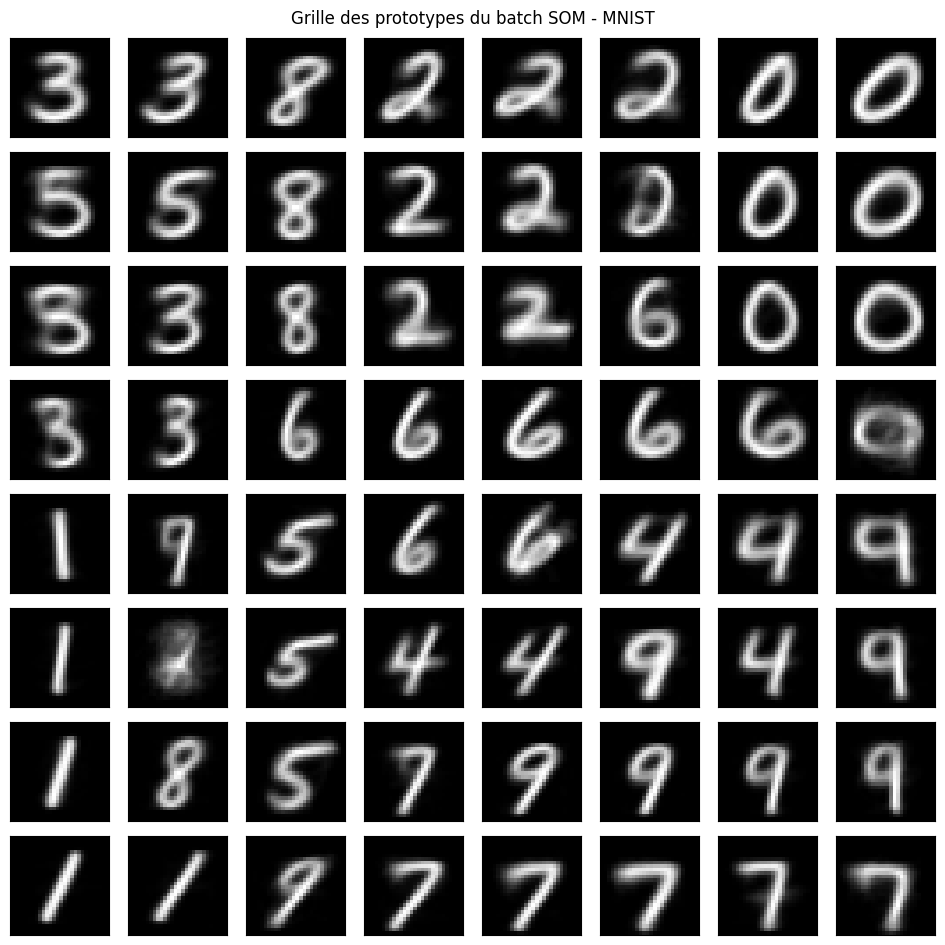

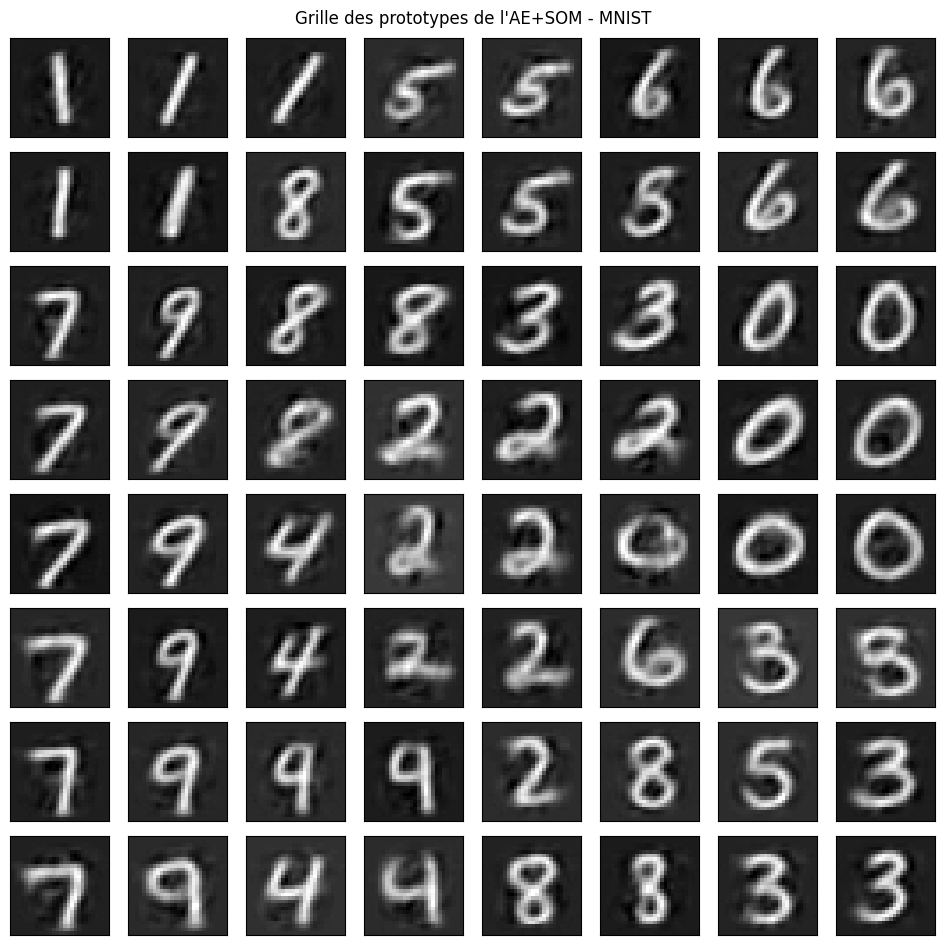

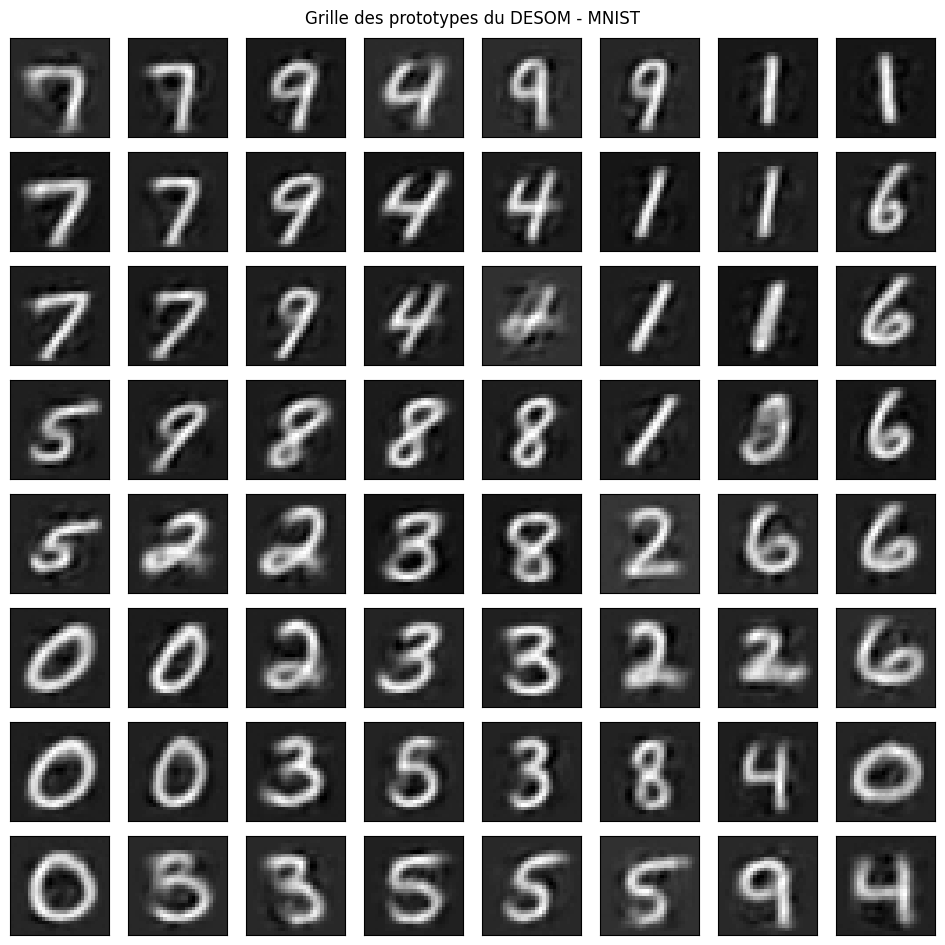

In [10]:
eval_utils.plot_prototype_grid(
    weights=weights_som,
    grid_size=grid_size,
    title="Grille des prototypes du batch SOM - MNIST",
    save_path=save_path / "prototype_grid_som.png",
)

eval_utils.plot_prototype_grid(
    weights=weights_ae_som,
    grid_size=grid_size,
    title="Grille des prototypes de l'AE+SOM - MNIST",
    decoder=ae_som_model.autoencoder.decodeur,
    save_path=save_path / "prototype_grid_ae_som.png",
)

eval_utils.plot_prototype_grid(
    weights=weights_desom,
    grid_size=grid_size,
    title="Grille des prototypes du DESOM - MNIST",
    decoder=Desom_model.ae.decodeur,
    save_path=save_path / "prototype_grid_desom.png",
)

## **U-matrices**

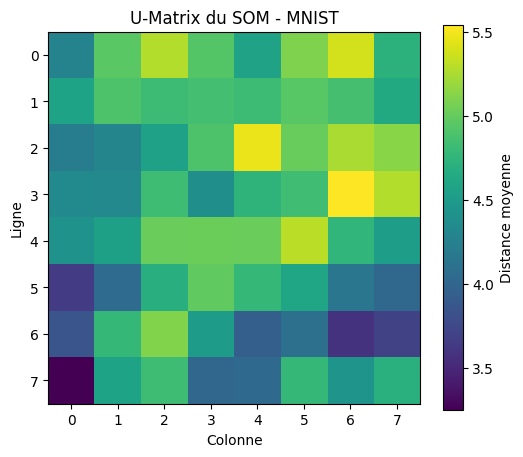

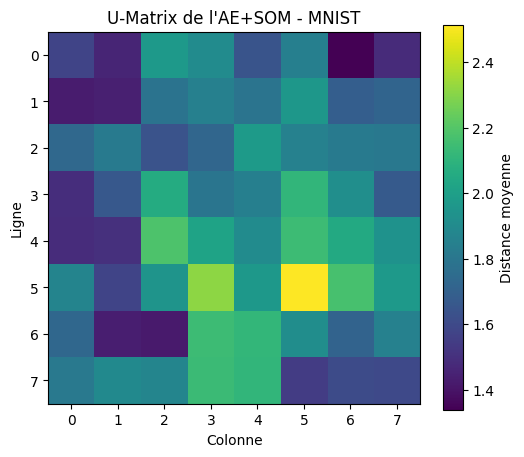

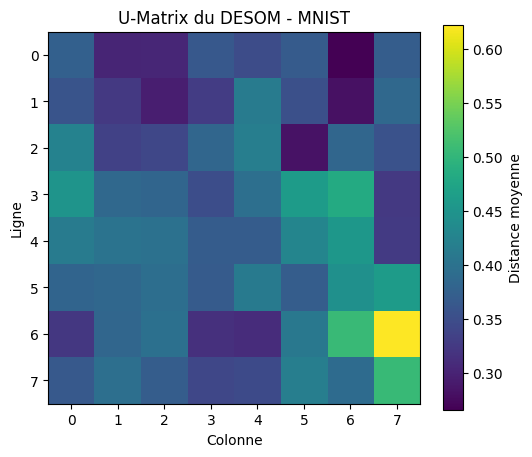

array([[0.37447965, 0.30263844, 0.30354345, 0.36286616, 0.3486824 ,
        0.36682132, 0.265082  , 0.36967286],
       [0.35806754, 0.32367897, 0.29535967, 0.32793435, 0.41282612,
        0.35280266, 0.2811074 , 0.38496366],
       [0.42385688, 0.33392087, 0.34086508, 0.38334924, 0.41804206,
        0.28263578, 0.38319492, 0.35465685],
       [0.44933215, 0.38564864, 0.38091129, 0.34872466, 0.39493608,
        0.46053177, 0.48354948, 0.32395852],
       [0.41405714, 0.40053844, 0.39757538, 0.36835861, 0.36848554,
        0.42733687, 0.45405632, 0.32574698],
       [0.3801752 , 0.38466766, 0.39376917, 0.3668642 , 0.41164899,
        0.36986205, 0.44457924, 0.46058473],
       [0.32231769, 0.38318139, 0.3969292 , 0.31488264, 0.30990553,
        0.40729389, 0.50740588, 0.62178355],
       [0.36529177, 0.39513969, 0.37081277, 0.34093881, 0.34454188,
        0.41744271, 0.38929263, 0.50575721]])

In [11]:
# batch SOM
eval_utils.plot_u_matrix(weights_som, grid_size, title="U-Matrix du SOM - MNIST", save_path=save_path / "u_matrix_som.png")

# AE+SOM
eval_utils.plot_u_matrix(weights_ae_som, grid_size, title="U-Matrix de l'AE+SOM - MNIST", save_path=save_path / "u_matrix_ae_som.png")

# DESOM
eval_utils.plot_u_matrix(weights_desom, grid_size, title="U-Matrix du DESOM - MNIST", save_path=save_path / "u_matrix_desom.png")


# **Hit maps**

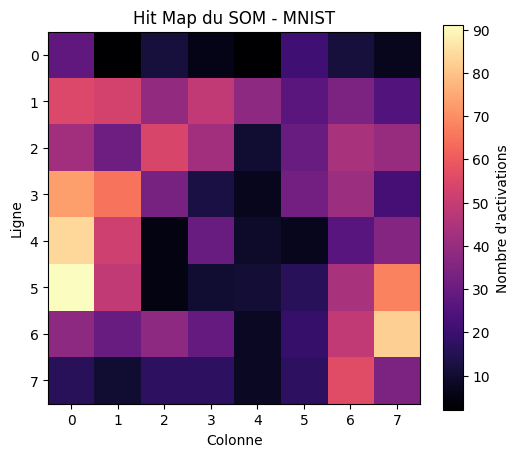

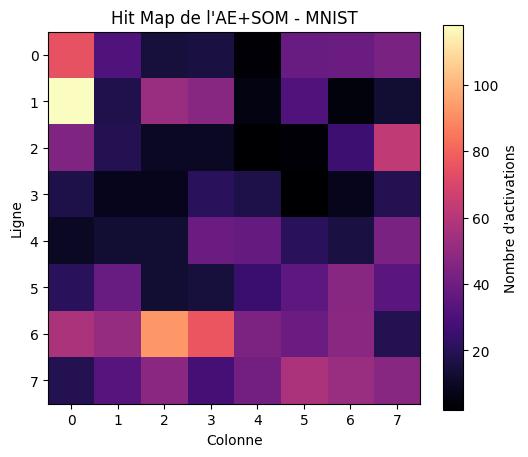

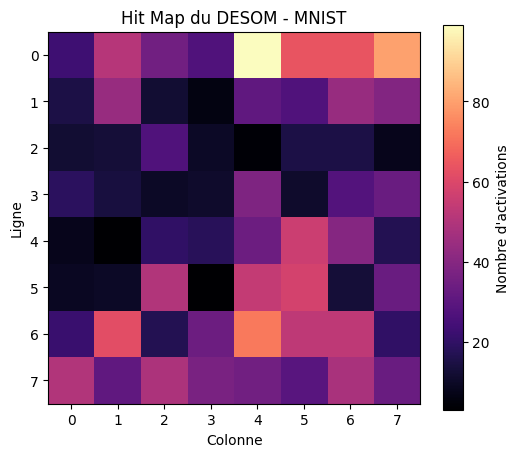

In [12]:
# batch SOM
eval_utils.hit_map(X_test, weights_som, grid_size, title="Hit Map du SOM - MNIST", save_path=save_path / "hit_map_som.png")

# AE+SOM
eval_utils.hit_map(Z_test, weights_ae_som, grid_size, title="Hit Map de l'AE+SOM - MNIST", save_path=save_path / "hit_map_ae_som.png")

# DESOM
eval_utils.hit_map(Z_test_desom, weights_desom, grid_size, title="Hit Map du DESOM - MNIST", save_path=save_path / "hit_map_desom.png")

## **Carte des prototypes MNIST**

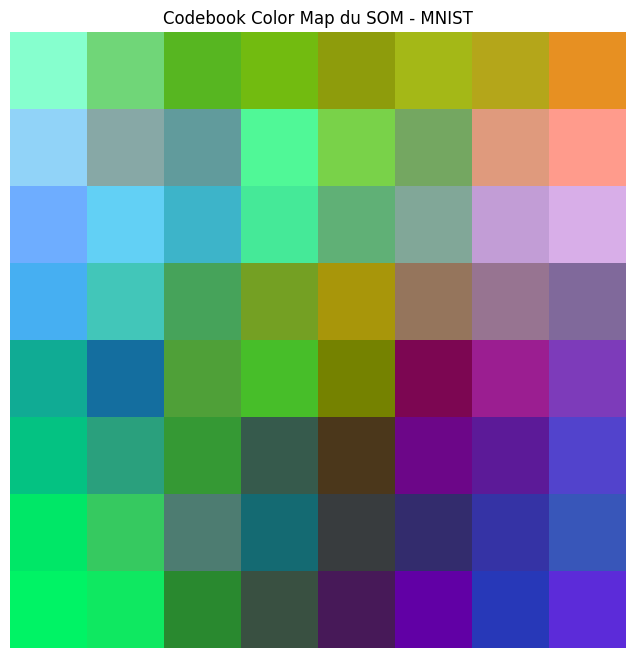

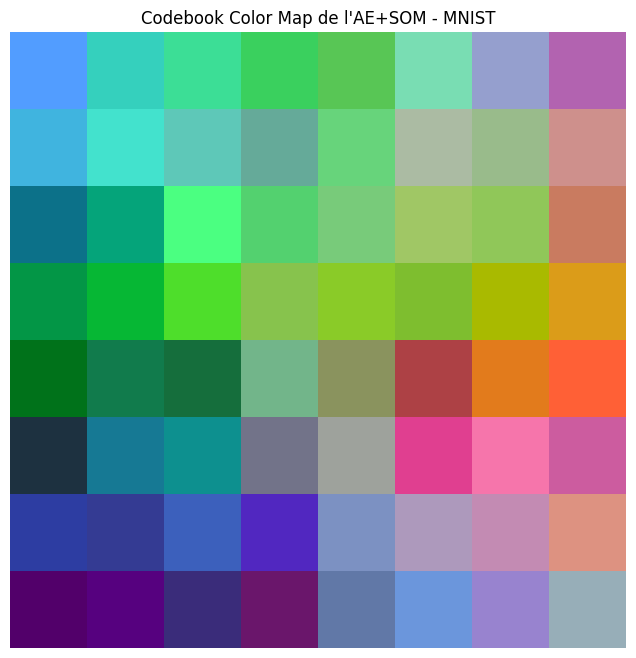

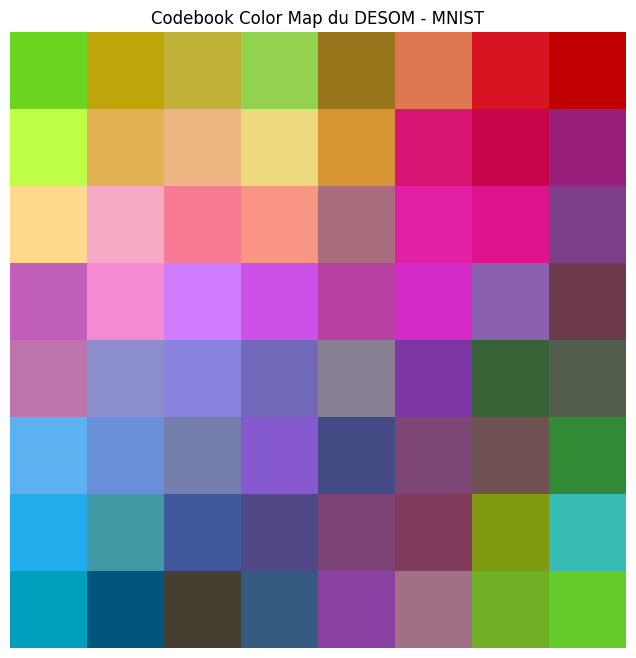

array([[[0.4125578 , 0.83738625, 0.13127387],
        [0.7475251 , 0.64926803, 0.05033019],
        [0.7562835 , 0.69802123, 0.22685862],
        [0.57787967, 0.82036513, 0.31836593],
        [0.6005861 , 0.46542808, 0.11336271],
        [0.8703641 , 0.47251877, 0.31954813],
        [0.8448205 , 0.08059817, 0.13619022],
        [0.7562275 , 0.        , 0.        ]],

       [[0.75652546, 1.        , 0.28614277],
        [0.88541406, 0.69814974, 0.3245356 ],
        [0.93240297, 0.7130748 , 0.51088625],
        [0.92787254, 0.85875833, 0.4899086 ],
        [0.8467241 , 0.58323973, 0.2019797 ],
        [0.8477693 , 0.08563242, 0.4475865 ],
        [0.785766  , 0.01853555, 0.29021263],
        [0.59744316, 0.12265515, 0.47918877]],

       [[1.        , 0.8548472 , 0.55465955],
        [0.96539885, 0.6661052 , 0.76528174],
        [0.96945894, 0.48413634, 0.587121  ],
        [0.97794265, 0.58450603, 0.52034366],
        [0.6682291 , 0.43080962, 0.49377784],
        [0.8824042 , 0.1260544

In [13]:
eval_utils.plot_codebook_color_map(
    weights=weights_som,
    grid_size=grid_size,
    title="Codebook Color Map du SOM - MNIST",
    save_path=save_path / "codebook_color_map_som.png"
)

eval_utils.plot_codebook_color_map(
    weights=weights_ae_som,
    grid_size=grid_size,
    title="Codebook Color Map de l'AE+SOM - MNIST",
    save_path=save_path / "codebook_color_map_ae_som.png"
)

eval_utils.plot_codebook_color_map(
    weights=weights_desom,
    grid_size=grid_size,
    title="Codebook Color Map du DESOM - MNIST",
    save_path=save_path / "codebook_color_map_desom.png"
)

## **Courbe d'apprentissage**

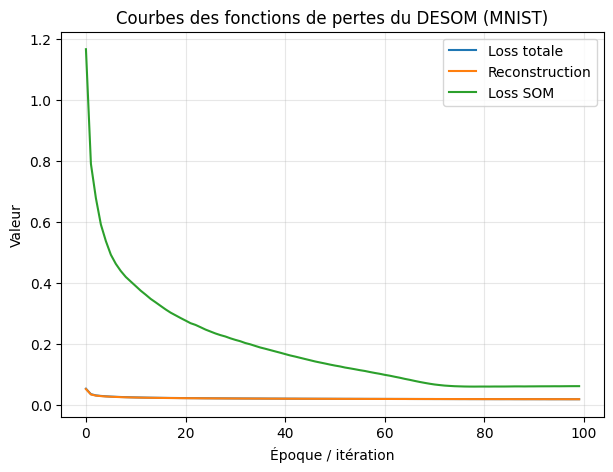

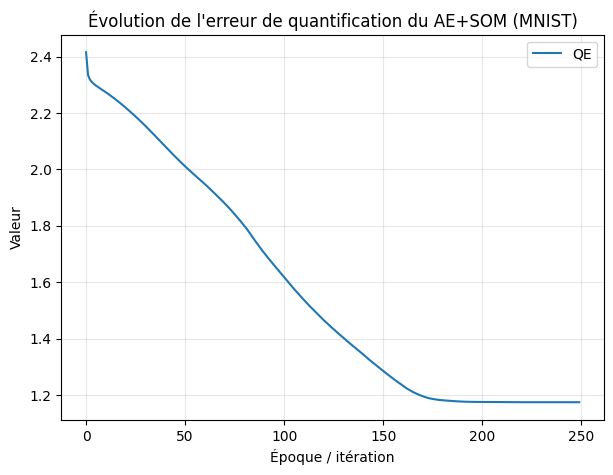

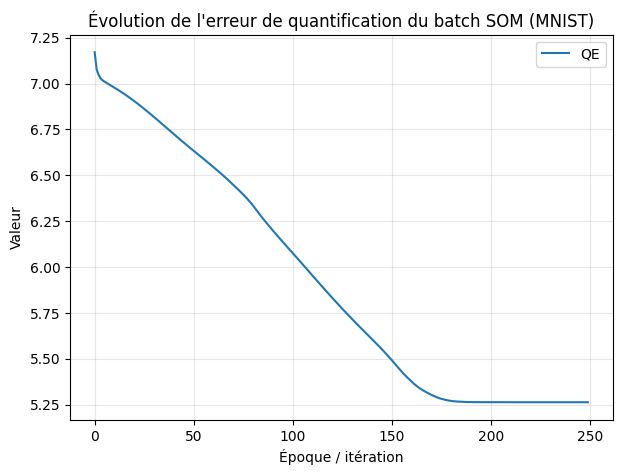

In [14]:
# DESOM
eval_utils.plot_training_curves(
    {
        "Loss totale": desom_losses["total"],
        "Reconstruction": desom_losses["reconstruction"],
        "Loss SOM": desom_losses["som"],
    },
    title="Courbes des fonctions de pertes du DESOM (MNIST)",
    save_path=save_path / "training_curves_desom.png"
)

# AE+SOM
eval_utils.plot_training_curves(
    {
        "QE": history_ae_som["QE"]
    },
    title="Évolution de l'erreur de quantification du AE+SOM (MNIST)",
    save_path=save_path / "training_curves_ae.png"
)

# batch SOM n'a pas de courbe d'apprentissage à proprement parler, mais on peut visualiser 
# l'évolution de la quantization error
eval_utils.plot_training_curves(history_som, title="Évolution de l'erreur de quantification du batch SOM (MNIST)", 
                                save_path=save_path / "training_curves_som.png")


## **Etude de la taille de grille** 

In [15]:
results = []
rayon_init = 8.0

for gs in [(6, 6),(8, 8),(10, 10),(12, 12),(15, 15)]:
    
    print(f"Grille: {gs}, Rayon init: {rayon_init}")
    print("en cours...")
    
    # =========================
    # batch SOM
    # =========================
    print("Entraînement du batch SOM...")
    batch_som = som.batchSOM(
        rayon_init= rayon_init, 
        grid_size=gs, 
        n_steps=250, 
        dis_choice="euclidean",
        calculate_qe=False 
    )

    weights_som, history_som = batch_som.train(X_train)

    results_som = eval_utils.evaluate_som_model(
        model_name="SOM",
        data=X_test,
        weights=weights_som,
        y_true=y_test,
        grid_size=gs,
        training_time=None
    )
    results.append(results_som)

    # =========================
    # AE+SOM
    # =========================
    print("Entraînement de l'AE+SOM...")
    ae_som_model = ae_som.AESOM(
        input_dim=784,
        latent_dim=10,
        rayon_init= rayon_init,
        grid_size=gs,
        n_steps_som=250, 
        weight_init="random",
        dis_choice="euclidean",
        topology="rectangular"
    )
    ae_losses, weights_ae_som = ae_som_model.train_ae_n_som(X_train)

    Z_test = ae_som_model.encode_latent(X_test)
    weights_ae_som, _ = weights_ae_som # on ne garde que les poids finaux du SOM pas l'historique

    results_ae_som = eval_utils.evaluate_som_model(
        model_name="AE+SOM",
        data=Z_test,
        weights=weights_ae_som,
        y_true=y_test,
        grid_size=gs,
        training_time=None
    )
    results.append(results_ae_som)

    # =========================
    # DESOM
    # =========================
    print("Entraînement du DESOM...")
    Desom_model = desom.DESOM(
    grid_size=gs,
    input_dim=784,
    latent_dim=10,
    n_epochs=100,
    batch_size=32,
    sigma_init= rayon_init,
    gamma=1e-3
    )

    desom_losses = Desom_model.embedded_train(X_train)

    Z_test_desom = Desom_model.encode(X_test).detach().cpu().numpy()

    weights_desom = Desom_model.som.weights.detach().cpu().numpy()

    results_desom = eval_utils.evaluate_som_model(
        model_name="DESOM",
        data=Z_test_desom,
        weights=weights_desom,
        y_true=y_test,
        grid_size=gs,
        training_time=None
    )
    results.append(results_desom)
    

df_results = pd.DataFrame(results)
df_results["n_noeuds"] = df_results["Grille"].apply(
    lambda s: int(s.split("x")[0]) * int(s.split("x")[1])
)

Grille: (6, 6), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...
Grille: (8, 8), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...
Grille: (10, 10), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...
Grille: (12, 12), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...
Grille: (15, 15), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...


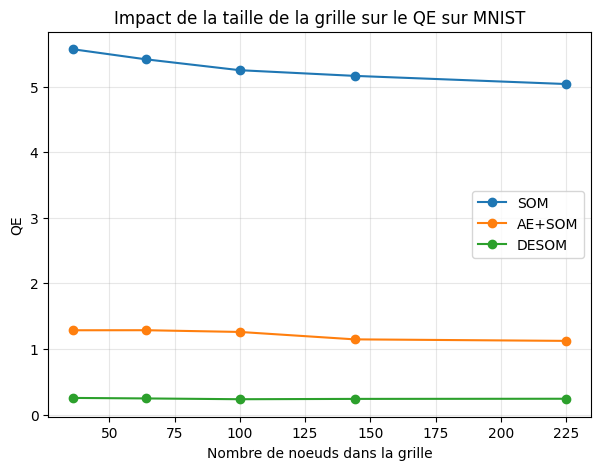

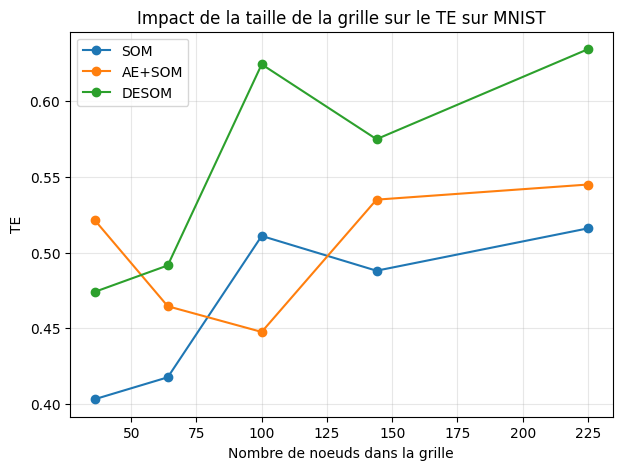

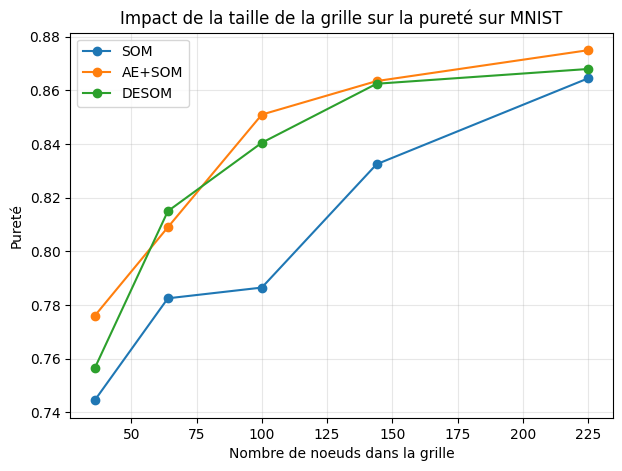

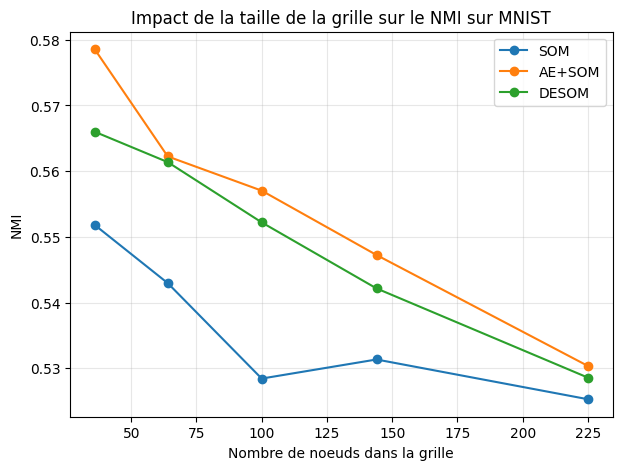

In [16]:
eval_utils.plot_grid_size_study(df_results, metric="QE", title="Impact de la taille de la grille sur le QE sur MNIST", save_path=save_path / "grid_size_study_qe.png")
eval_utils.plot_grid_size_study(df_results, metric="TE", title="Impact de la taille de la grille sur le TE sur MNIST", save_path=save_path / "grid_size_study_te.png")
eval_utils.plot_grid_size_study(df_results, metric="Pureté", title="Impact de la taille de la grille sur la pureté sur MNIST", save_path=save_path / "grid_size_study_purete.png")
eval_utils.plot_grid_size_study(df_results, metric="NMI", title="Impact de la taille de la grille sur le NMI sur MNIST", save_path=save_path / "grid_size_study_nmi.png")
